```{contents}
:local:
:depth: 2
```

# 1.4 Linear Programming

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 3, Lesson 1: *Linear and Mixed-Integer Linear Formulations*
- Module 3, Lesson 2: *Graphical Solutions of Linear Problems*
- Module 3, Lesson 6: *Linear Programming Example*

Lesson 1 also introduces mixed-integer linear formulations; we read that half in Topic 2.4. Lesson 6 works a two-product production-planning example (from J. C. Kantor's Pyomo Cookbook) and reads its active constraints. This topic does the same on the electrolyzer fleet. Lessons 3 to 5, on the simplex method, are Topic 1.5.
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Recognize a linear program and list the kinds of engineering problems that are written as LPs.
- Draw the feasible region and objective contours of a two-variable LP and locate its optimum at a vertex.
- Read constraint duals and reduced costs from a solver as sensitivities, and check their sign with a finite difference.
- Explain how a demand constraint on the water-electrolysis LP prices hydrogen, and how the dispatch LP turns that price into a merit order.
:::

A **linear program** (LP) is an optimization problem where we minimize or maximize a linear function of continuous variables, subject to constraints that are linear equalities and inequalities. We can write any LP in matrix form as:

$$
\min_x \; c^\top x \quad \text{s.t.} \quad A x \le b, \quad A_{\mathrm{eq}} x = b_{\mathrm{eq}}, \quad \ell \le x \le u .
$$

In Topic 1.2 we already solved two LPs: water electrolysis with the gases drawn off at fixed pressure, and the dispatch of three electrolyzer stacks (without the fixed charges). In this topic we will look at the class in more detail. First we will see why so many problems are written as LPs, then we will draw an LP to see where its solution has to sit, and finally we will read the extra numbers a solver returns along with the solution. It turns out these extra numbers are often the most useful part of the answer.

## Linear programs in engineering

If we have the choice, we would like every model to be linear. Remember that LPs are convex (Topic 1.1), so the optimum found by a solver is the global optimum. They are also fast, since production solvers can handle LPs with millions of variables and constraints. Some problems are nonlinear by nature and cannot be made linear. However, many others only look nonlinear at first, and become linear once we choose the right variables. Formulation is a skill, and a lot of that skill consists of finding those variables.

To give a sense of the range, here is a short list of problems that are routinely solved as LPs:

- planning and scheduling of production in chemical and petrochemical plants (which products to make, and how much);
- blending (refinery products, animal feed, alloys) to meet specifications at least cost;
- network flows: product through a pipeline network, or goods from warehouses to customers;
- electric power dispatch: which generators meet a load, and at what output, at least cost;
- transportation and airline planning: train and bus timetables, crew and route assignments, seat pricing (multicommodity flows, where several products share one network).

The last item is the closest relative of our electrolyzer fleet, and we will borrow some of the vocabulary of power-system economics (merit order, marginal unit, capacity rent) below.

Despite the nonlinearity of nature, many of these models are linear, or they are linear approximations that are accurate enough to plan with. If we add yes-or-no decisions to the same list (e.g. build this warehouse, or switch on this stack), it becomes the list of mixed-integer linear programs (MILPs), and the integer decisions open up even more applications: supply-chain design, the knapsack problem of Topic 1.3, panel and committee assignment, protein design and structure prediction, selecting the relevant symptoms for a diagnosis, and training some machine-learning models. When every variable is discrete, the problem is called an integer linear program (ILP). In all of these cases the functions must stay linear, so a product of a continuous and a discrete variable, $x \cdot y$, is not allowed in an MILP. We will return to MILP formulations in {doc}`../2-nonlinear_mixed_integer/Topic2.4-Mixed-Integer_Formulations`.

The reason LPs are tractable is geometric. The feasible region of an LP is a convex polyhedron (i.e. an intersection of half-spaces), and a linear objective has no curvature, so it cannot have an interior minimum: moving in the direction of $-c$ always helps until we hit a constraint. This leads to a key result: **if an LP has an optimal solution, then at least one vertex (corner) of the feasible region is optimal.** Since a polyhedron has finitely many vertices, the search for an optimum among infinitely many feasible points reduces to a search among finitely many corners. George Dantzig turned this observation into the simplex method in the late 1940s, while working on planning problems for the US Air Force. We will develop the method in Topic 1.5, and here we will just look at the corners directly.

The theory is old, but LP and MILP solvers have become orders of magnitude faster over the last few decades through better algorithms, presolve, heuristics and parallel computing. Today an LP with millions of variables is routine, and commercial MILP solvers (Gurobi, CPLEX, Xpress) and open-source ones (HiGHS, CBC, from the COIN-OR project) solve hard MILPs with thousands of binaries, sometimes in seconds. H. Mittelmann maintains public benchmarks comparing them (https://plato.asu.edu/bench.html).

Here is the fleet LP from Topic 1.2 again, written for `scipy.optimize.linprog` and solved. Stacks A, B and C have specific energies $e = (1.2, 1.45, 1.7)$ in per-unit power per unit load, each has capacity 1 (200 kg H2/h), and together they must make $D = 1.2$ (240 kg/h):

$$
\min_{x} \; 1.2\, x_A + 1.45\, x_B + 1.7\, x_C \quad \text{s.t.} \quad x_A + x_B + x_C = 1.2, \quad 0 \le x_i \le 1 .
$$

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from scipy.optimize import linprog
import pyomo.environ as pyo
from _lib import electrolyzer as el
from _lib.part1_tools import get_solver

highs = get_solver('appsi_highs')
e = np.array([el.E_LINEAR[i] for i in el.NAMES])
D = 1.2
lp = linprog(e, A_eq=[np.ones(3)], b_eq=[D], bounds=[(0, 1)] * 3)
print(f"x* = {np.round(lp.x, 3)}, power {lp.fun:.3f} per-unit = {el.to_mw(lp.fun):.2f} MW")

x* = [1.  0.2 0. ], power 1.490 per-unit = 9.74 MW


### Absolute values in an LP

Some functions that are not linear can still be written as LPs, and the most useful case is the absolute value. Suppose we measure the power drawn by stack B at ten loads and want to estimate its specific energy $e$ and an offset $p_0$ by fitting $P \approx p_0 + e\,x$. Least squares minimizes $\sum_k r_k^2$ for residuals $r_k = P_k - p_0 - e x_k$. Minimizing $\sum_k |r_k|$ instead is less sensitive to a bad measurement, but $|r_k|$ is not linear, so we introduce one new variable $t_k$ per residual and two linear constraints that make it an upper bound on $|r_k|$:

$$
\min_{p_0, e, t} \; \sum_k t_k \quad \text{s.t.} \quad -t_k \le P_k - p_0 - e\,x_k \le t_k .
$$

At the optimum each $t_k$ gets pushed down onto $|r_k|$, since there is nothing else holding it up. The same trick also linearizes $\max_k |r_k|$ (with one shared $t$), and it works whenever an absolute value is being *minimized*. However, maximizing an absolute value is a different problem, and it is non-convex.

In [2]:
rng = np.random.default_rng(4)
xk = np.linspace(0.1, 1.0, 10)
Pk = 1.45 * xk + rng.normal(0, 0.01, xk.size)
Pk[7] += 0.3                                                    # one faulty reading
K = xk.size
# variables: p0, e, t_1..t_K  (p0 and e free, t >= 0)
cost = np.r_[0, 0, np.ones(K)]
A_ub = np.block([[-np.ones((K, 1)), -xk[:, None], -np.eye(K)],    #  P - p0 - e x <= t
                 [np.ones((K, 1)), xk[:, None], -np.eye(K)]])     # -(P - p0 - e x) <= t
b_ub = np.r_[-Pk, Pk]
lad = linprog(cost, A_ub=A_ub, b_ub=b_ub, bounds=[(None, None)] * 2 + [(0, None)] * K)
ls = np.polyfit(xk, Pk, 1)
print(f"absolute-error LP: e = {lad.x[1]:.3f}, p0 = {lad.x[0]:+.3f}")
print(f"least squares:     e = {ls[0]:.3f}, p0 = {ls[1]:+.3f}   (true e = 1.45, p0 = 0)")

absolute-error LP: e = 1.454, p0 = -0.003
least squares:     e = 1.534, p0 = -0.018   (true e = 1.45, p0 = 0)


The absolute-error fit stays close to the true slope despite the faulty reading, whereas least squares gets pulled toward the bad point. The lectures apply the same trick to the equation-of-state fit of Topic 1.2, where it makes the objective linear although the model itself stays nonlinear.

:::{exercise}
:label: ex-t14-formulation

A stack's specific energy is not constant in practice: suppose stack B uses 1.35 per unit for its first half of load and 1.55 per unit for its second half. Write this as an LP by splitting $x_B$ into two variables $x_{B1}, x_{B2} \in [0, 0.5]$, and solve it. Why does the solver never fill $x_{B2}$ before $x_{B1}$, even though nothing in the model says it must? What would go wrong if the second half were *cheaper* than the first?
:::

## Graphical solution

Since a two-variable LP can be drawn, and the drawing shows all of the steps of the simplex method, it is worth reducing the fleet LP to two variables. It has three variables and one equality, which leaves two degrees of freedom, so if we eliminate $x_C = 1.2 - x_A - x_B$ the bounds $0 \le x_C \le 1$ become $0.2 \le x_A + x_B \le 1.2$ and the objective becomes

$$
1.2\, x_A + 1.45\, x_B + 1.7\,(1.2 - x_A - x_B) = 2.04 - 0.5\, x_A - 0.25\, x_B .
$$

In the $(x_A, x_B)$ plane the feasible region is the unit square with two corners cut off by the lines $x_A + x_B = 0.2$ and $x_A + x_B = 1.2$, which gives a hexagon. The contours of the objective are parallel straight lines, so to minimize we slide a contour in the direction of decreasing power until it is about to leave the region, and the last point it touches is the optimum. The code below prints the power at each vertex and draws the picture:

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


vertex (x_A, x_B, x_C) = (0.2, 0.0, 1.0): power 1.94
vertex (x_A, x_B, x_C) = (1.0, 0.0, 0.2): power 1.54
vertex (x_A, x_B, x_C) = (1.0, 0.2, 0.0): power 1.49
vertex (x_A, x_B, x_C) = (0.2, 1.0, 0.0): power 1.69
vertex (x_A, x_B, x_C) = (0.0, 1.0, 0.2): power 1.79
vertex (x_A, x_B, x_C) = (0.0, 0.2, 1.0): power 1.99


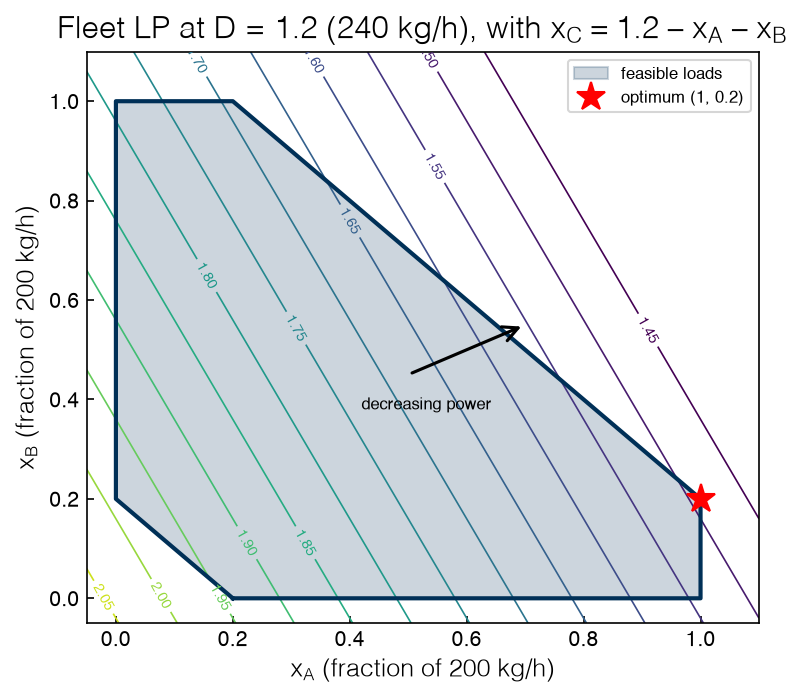

In [3]:
# vertices of the feasible hexagon, in order around the boundary
V = np.array([[0.2, 0.0], [1.0, 0.0], [1.0, 0.2], [0.2, 1.0], [0.0, 1.0], [0.0, 0.2]])
power = lambda xa, xb: 2.04 - 0.5 * xa - 0.25 * xb
for xa, xb in V:
    print(f"vertex (x_A, x_B, x_C) = ({xa:.1f}, {xb:.1f}, {abs(1.2 - xa - xb):.1f}): power {power(xa, xb):.2f}")

xa, xb = np.meshgrid(np.linspace(-0.05, 1.1, 200), np.linspace(-0.05, 1.1, 200))
fig, ax = plt.subplots(figsize=(5.5, 5))
cs = ax.contour(xa, xb, power(xa, xb), levels=np.arange(1.45, 2.1, 0.05), cmap='viridis', linewidths=0.8)
ax.clabel(cs, fmt='%.2f', fontsize=7)
ax.fill(V[:, 0], V[:, 1], alpha=0.2, color='C0', label='feasible loads')
ax.plot(*np.vstack([V, V[:1]]).T, 'C0-')
ax.plot(1.0, 0.2, 'r*', ms=14, label='optimum (1, 0.2)')
ax.annotate('', xy=(0.7, 0.55), xytext=(0.5, 0.45), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.text(0.42, 0.38, 'decreasing power', fontsize=8)
ax.set_xlabel('$x_A$ (fraction of 200 kg/h)')
ax.set_ylabel('$x_B$ (fraction of 200 kg/h)')
ax.set_title('Fleet LP at D = 1.2 (240 kg/h), with $x_C = 1.2 - x_A - x_B$')
ax.legend(loc='upper right', fontsize=8);

The contour labels are the total power in per-unit. The steepest descent direction, $(0.5, 0.25)$, points up and to the right, so the best point is the corner that is farthest in that direction, $(x_A, x_B) = (1, 0.2)$, with $x_C = 0$ and a power of 1.49. We can also see from the table of vertices that this is the lowest of the six. There are two **active** constraints at this point (i.e. constraints that hold with equality), $x_A \le 1$ and $x_C \ge 0$, and in a two-dimensional picture two active constraints pin down a single point, which is exactly what a vertex is.

The picture also shows us when the answer would *not* be unique. If the contours were parallel to an edge of the hexagon, then the whole edge would be optimal. This happens when two stacks have the same specific energy, and it also happens in the water LP of Topic 1.2 at exactly $U = E^0$, where the objective is flat along the entire feasible segment. Problems like this are called **degenerate**, and we will see in Topic 1.5 why they need some care.

We can think of the water LP of Topic 1.2 as the one-dimensional version of this picture. It has one mole of water, four variables and three balances, so its feasible region is a segment going from "all water" to "all hydrogen and oxygen". The objective is a straight line along this segment, and so the optimum has to be whichever end is lower.

:::{exercise}
:label: ex-t14-graphical

Redraw the figure with $e_C = 1.3$ instead of 1.7. Which vertex is optimal now, and what is the merit order? Then find a value of $e_C$ at which an entire edge of the hexagon is optimal, and draw that case.
:::

## The demand row: pricing hydrogen

In addition to the solution of an LP, a solver returns a set of **sensitivities**: how much the optimal objective would change if a constraint were relaxed a little. We will start with the water-electrolysis LP, since in this case the sensitivity of a single new constraint is something we have already seen in thermodynamics.

Remember that in the LP from Topic 1.2 one mole of liquid water sits in a cell, and the gases are removed at 1 bar so each gas has a fixed chemical potential $\mu^0_i$. A power supply pushes $q$ moles of electrons through the cell at voltage $U$, which gives the following LP:

$$
\begin{aligned}
\min_{n, q \ge 0} \quad & -\Delta G^0\, n_{\mathrm{H_2O}} - F U q \\
\text{s.t.} \quad & 2 n_{\mathrm{H_2O}} + 2 n_{\mathrm{H_2}} = 2, \qquad n_{\mathrm{H_2O}} + 2 n_{\mathrm{O_2}} = 1, \qquad q - 2 n_{\mathrm{H_2}} = 0 .
\end{aligned}
$$

Below the reversible voltage $E^0 = 1.229$ V nothing happens, since the optimum sits at the vertex "all water" and no hydrogen gets made. Now we will give the cell a customer by adding one more row, a **demand constraint** requiring at least $D$ moles of hydrogen:

$$
n_{\mathrm{H_2}} \ge D .
$$

Now the LP has to split $D$ moles of water whether it wants to or not. To see how much this raises the objective, we can solve it in Pyomo, read the dual of the new row, and then check it with a finite difference:

In [4]:
F, DG0, E0 = el.F_CONST, el.DG0, el.E0

def kernel_lp(U, D=0.0):
    """Water electrolysis with gases drawn off at 1 bar (Topic 1.2), plus a demand row n_H2 >= D."""
    m = pyo.ConcreteModel()
    m.nw, m.nh, m.no, m.q = (pyo.Var(within=pyo.NonNegativeReals) for _ in range(4))
    m.G = pyo.Objective(expr=-DG0 * m.nw - F * U * m.q)            # J; mu0 = 0 for H2 and O2
    m.H = pyo.Constraint(expr=2 * m.nw + 2 * m.nh == 2)
    m.O = pyo.Constraint(expr=m.nw + 2 * m.no == 1)
    m.charge = pyo.Constraint(expr=m.q - 2 * m.nh == 0)
    m.demand = pyo.Constraint(expr=m.nh >= D)
    m.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
    highs.solve(m)
    return m

for U in (0.0, 1.0):
    base = pyo.value(kernel_lp(U).G)
    print(f"U = {U:.1f} V (below E0 = {E0:.3f} V); without the demand row: n_H2 = {pyo.value(kernel_lp(U).nh):.1f}")
    for Dh in (0.2, 0.4):
        mD = kernel_lp(U, Dh)
        fd = (pyo.value(kernel_lp(U, Dh + 1e-4).G) - pyo.value(mD.G)) / 1e-4
        print(f"   D = {Dh}: n_H2 = {pyo.value(mD.nh):.1f}, objective rises by {(pyo.value(mD.G) - base) / 1e3:6.2f} kJ; "
              f"dual of demand row {mD.dual[mD.demand] / 1e3:6.2f} kJ/mol; finite difference {fd / 1e3:6.2f} kJ/mol")
    print(f"   compare  DG0 - 2FU = {(DG0 - 2 * F * U) / 1e3:.2f} kJ/mol")

U = 0.0 V (below E0 = 1.229 V); without the demand row: n_H2 = 0.0


   D = 0.2: n_H2 = 0.2, objective rises by  47.43 kJ; dual of demand row 237.13 kJ/mol; finite difference 237.13 kJ/mol


   D = 0.4: n_H2 = 0.4, objective rises by  94.85 kJ; dual of demand row 237.13 kJ/mol; finite difference 237.13 kJ/mol
   compare  DG0 - 2FU = 237.13 kJ/mol


U = 1.0 V (below E0 = 1.229 V); without the demand row: n_H2 = 0.0


   D = 0.2: n_H2 = 0.2, objective rises by   8.83 kJ; dual of demand row  44.16 kJ/mol; finite difference  44.16 kJ/mol


   D = 0.4: n_H2 = 0.4, objective rises by  17.66 kJ; dual of demand row  44.16 kJ/mol; finite difference  44.16 kJ/mol
   compare  DG0 - 2FU = 44.16 kJ/mol


We can see that the dual of the demand row is constant in $D$, and it is equal to $\Delta G^0 - 2FU$ per mole of hydrogen. With no power supply ($U = 0$) it is $\Delta G^0 = 237.13$ kJ/mol, and at $U = 1.0$ V the supply pays for part of the split, which leaves a cost of 44.16 kJ/mol. The finite differences agree to all the digits shown.

**Reading the sign.** Pyomo reports the dual of a minimization as the derivative of the objective with respect to the right-hand side, $\partial G^*/\partial D$, and here it is positive, since more demand costs more. However, other interfaces use other conventions. For example, `scipy.optimize.linprog` only accepts $\le$ rows, so we have to write $n_{\mathrm{H_2}} \ge D$ as $-n_{\mathrm{H_2}} \le -D$, and then scipy reports a *negative* marginal for it (the derivative with respect to $-D$). There is no need to memorize these conventions. Instead, you can perturb the right-hand side once, as we did above, and let the finite difference fix the sign:

In [5]:
A_eq = np.array([[2, 2, 0, 0], [1, 0, 2, 0], [0, -2, 0, 1]])     # columns: n_H2O, n_H2, n_O2, q
res = linprog([-DG0, 0, 0, 0], A_eq=A_eq, b_eq=[2, 1, 0], A_ub=[[0, -1, 0, 0]], b_ub=[-0.2], bounds=[(0, None)] * 4)
print(f"scipy, U = 0, D = 0.2: ineqlin.marginals = {res.ineqlin.marginals[0] / 1e3:.2f} kJ/mol  (= -dG*/dD)")

scipy, U = 0, D = 0.2: ineqlin.marginals = -237.13 kJ/mol  (= -dG*/dD)


Now we can read the result twice, first in thermodynamic terms and then in economic terms. Both readings describe the same number, although we will keep them in separate paragraphs.

*Thermodynamic reading.* The dual of the demand row is the part of the reaction Gibbs energy not covered by the power supply, $\Delta G^0 - 2FU$, i.e. the minimum extra work needed to drive one more mole of water uphill to hydrogen and oxygen. Without a power supply the dual is the full $\Delta G^0 = 237.13$ kJ/mol, which is the reversible work of electrolysis. Above $E^0$ the cell splits all of the water on its own, so the demand row is slack and its dual is zero.

*Economic reading.* The dual is the price of meeting the customer's order at the margin, or the cost of delivering one more mole of hydrogen. A product the plan does not make on its own, because its cost exceeds its value, is said to be **priced out**, and forcing it into the plan costs exactly its reduced cost per unit. In the base LP hydrogen is priced out by $\Delta G^0 - 2FU$, and the demand row turns that reduced cost into a bill.

The value at $U = 0$ is the number that every topic through 2.6 builds on, because one mole of hydrogen made reversibly from liquid water at 298 K costs $\Delta G^0 = 237.13$ kJ, and this is the unit of power in the per-unit convention of Topic 1.1. A stack running at full load with no losses would draw 1 per-unit, or 6.535 MW, which is 27.56 mol/s of hydrogen times 237.13 kJ/mol. From here on the chemistry is fixed at that price, and the question becomes which stacks should do the work.

:::{exercise}
:label: ex-t14-demand-row

Sweep the voltage from $U = 0$ to $1.4$ V at fixed $D = 0.2$, and plot the dual of the demand row (kJ/mol) against $U$, together with the line $\Delta G^0 - 2FU$. Where do they part company, and why? Then repeat the sweep for the dual of the charge balance, `m.dual[m.charge]`, and compare it with $-FU$. (Some values may not match: Topic 1.5 explains that the duals of a degenerate vertex are not unique.)
:::

## The dispatch LP: merit order and prices

The fleet LP is the second half of this story, on the production side. Its chemistry is fixed at the price we just found, so every unit of load is a quantity of hydrogen with an ideal cost of 1 per-unit. Each stack spends more than the ideal, $e_i = 1 + \ell_i$ per unit, where $\ell_i$ is a linear loss, and the question is how to split the demand among the stacks.

The answer is a rule power engineers call the **merit order**: we sort the units by marginal cost and load them, cheapest first, until the demand is met. The last unit to be loaded is the **marginal unit**, the only one running between its bounds. In this case the order is A ($e = 1.2$), B ($1.45$), C ($1.7$), so A fills to capacity, B takes the remaining 0.2, and C stays off. The LP solver finds the same answer without being told the rule, and also returns three sensitivities. Let's read them one at a time:

In [6]:
def fleet_lp(D=1.2, cap=None):
    cap = cap or {i: 1.0 for i in el.NAMES}
    m = pyo.ConcreteModel()
    m.S = pyo.Set(initialize=el.NAMES)
    m.x = pyo.Var(m.S, bounds=lambda m, i: (0, cap[i]))
    m.demand = pyo.Constraint(expr=sum(m.x[i] for i in m.S) == D)
    m.power = pyo.Objective(expr=sum(el.E_LINEAR[i] * m.x[i] for i in m.S))
    m.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
    m.rc = pyo.Suffix(direction=pyo.Suffix.IMPORT)
    highs.solve(m)
    return m

m = fleet_lp()
P0 = pyo.value(m.power)
print(f"loads {[round(pyo.value(m.x[i]), 3) for i in m.S]}, power {P0:.3f} per-unit = {el.to_mw(P0):.2f} MW")
print(f"demand dual      {m.dual[m.demand]:.3f}")
print(f"reduced costs    {dict((i, round(m.rc[m.x[i]], 3)) for i in m.S)}")

h = 1e-3
fd_D = (pyo.value(fleet_lp(D=1.2 + h).power) - P0) / h
mC = fleet_lp(); mC.x['C'].setlb(h); highs.solve(mC)                   # force stack C to carry a little load
fd_C = (pyo.value(mC.power) - P0) / h
fd_A = (pyo.value(fleet_lp(cap={'A': 1 + h, 'B': 1.0, 'C': 1.0}).power) - P0) / h
print(f"finite differences: dP*/dD = {fd_D:.3f}; forcing C on: {fd_C:+.3f}; raising A's capacity: {fd_A:+.3f}")

loads [1.0, 0.2, 0.0], power 1.490 per-unit = 9.74 MW
demand dual      1.450
reduced costs    {'A': -0.25, 'B': 0.0, 'C': 0.25}


finite differences: dP*/dD = 1.450; forcing C on: +0.250; raising A's capacity: -0.250


**The demand dual, 1.45.** If we add one more unit of demand, the total power goes up by 1.45 per-unit, since the extra hydrogen comes from the marginal stack, B. This means that the demand dual is equal to the specific energy of the marginal unit. In real units, 1.45 per-unit is $1.45 \times 237.13 = 344$ kJ per mole of hydrogen, or 47.4 kWh per kilogram. This is the **hydrogen price** of the fleet: the marginal energy cost of one more kilogram.

**The reduced cost of C, 0.25.** Stack C is off (at its lower bound), and if we force it to carry a small load $\delta$ it displaces the same load from B, which costs $(1.7 - 1.45)\,\delta$. We say that stack C is **priced out** by 0.25, since its cost is higher than the going price of hydrogen by that much. This is the same phrase we used for hydrogen in the water LP, and it means the same thing: an activity is left out of the plan because its cost is above its value, by an amount equal to its reduced cost.

**The capacity rent on A, 0.25.** Stack A is at its upper bound, and if it were slightly larger its extra output would displace B and save $1.45 - 1.2 = 0.25$ per unit. Pyomo reports this as a reduced cost of $-0.25$ on $x_A$ (a negative reduced cost at an upper bound means raising the bound helps). Economists refer to this as the **capacity rent**: the value of an extra unit of capacity on a cheap unit, i.e. the hydrogen price minus the unit's own cost. In scipy the same number shows up in `res.upper.marginals` as $-0.25$, and as before the finite difference fixes the sign.

A solver's duals are useful because each one answers a "what if" question without a re-solve. Why they exist, and why they come in matched pairs with the solution, is the subject of duality in {doc}`../2-nonlinear_mixed_integer/Topic2.3-Duality`, so for now we will use them as sensitivities and check them with finite differences.

The merit order also has a familiar picture. If we stack the capacity of each unit along the horizontal axis in order of cost, and draw its specific energy as the height, we get a staircase, which is the **supply curve** of the fleet. The demand is a vertical line, and the price is the height of the step it crosses:

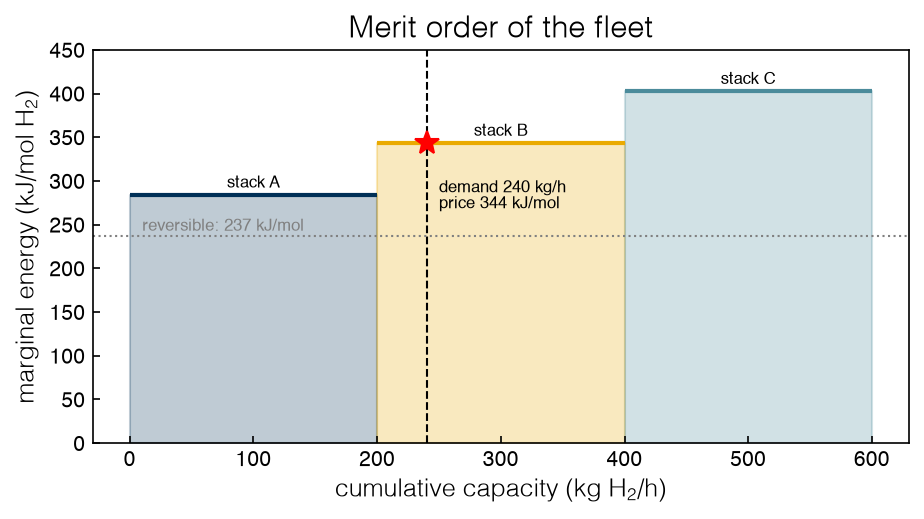

In [7]:
order = sorted(el.NAMES, key=lambda i: el.E_LINEAR[i])
edges = np.r_[0, np.cumsum([1.0] * 3)]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for k, i in enumerate(order):
    ekj = el.E_LINEAR[i] * DG0 / 1e3                                   # kJ per mol H2
    ax.fill_between(el.to_kg_h(edges[k:k + 2]), 0, ekj, step='pre', alpha=0.25, color=f'C{k}')
    ax.hlines(ekj, *el.to_kg_h(edges[k:k + 2]), color=f'C{k}')
    ax.text(el.to_kg_h(edges[k] + 0.5), ekj + 8, f'stack {i}', ha='center', fontsize=8)
ax.axvline(el.to_kg_h(D), color='k', ls='--', lw=1)
ax.axhline(DG0 / 1e3, color='grey', ls=':', lw=1)
ax.text(10, DG0 / 1e3 + 6, 'reversible: 237 kJ/mol', fontsize=8, color='grey')
ax.plot(el.to_kg_h(D), 1.45 * DG0 / 1e3, 'r*', ms=12)
ax.text(el.to_kg_h(D) + 10, 1.45 * DG0 / 1e3 - 75, 'demand 240 kg/h\nprice 344 kJ/mol', fontsize=8)
ax.set_xlabel('cumulative capacity (kg H$_2$/h)')
ax.set_ylabel('marginal energy (kJ/mol H$_2$)')
ax.set_ylim(0, 450)
ax.set_title('Merit order of the fleet');

We read the price twice more, again in separate paragraphs.

*Thermodynamic reading.* Divided by $2F$, a marginal energy per mole of hydrogen is a voltage, so the fleet's price of 344 kJ/mol is 1.78 V-equivalent, the effective voltage of the marginal stack. How this compares with the kernel's reversible voltage is taken up in {doc}`../2-nonlinear_mixed_integer/Topic2.3-Duality`.

*Economic reading.* At an electricity price of \$0.05/kWh, a marginal 47.4 kWh/kg is \$2.37 per kilogram of hydrogen: what the plant spends on electricity to make one more kilogram. The 45–55 kWh/kg of real alkaline and PEM plants is in the same range, so the stylized fleet behaves like a real one.

:::{exercise}
:label: ex-t14-merit-order

Solve the fleet LP for $D$ from 0.1 to 3.0, and plot the demand dual (kJ/mol) and the total power (MW) against the demand (kg/h). Mark on the plot where each stack becomes the marginal unit. At $D = 2.0$ exactly, what does the solver report for the demand dual, and what do finite differences from below and from above give? Explain the difference.
:::

## Summary

- An LP has continuous variables, a linear objective and linear constraints. Its feasible region is a convex polyhedron, and if an optimum exists, a vertex is optimal. Planning, blending, network flow and dispatch problems are routinely written as LPs.
- The fleet LP at $D = 1.2$ is a hexagon in the $(x_A, x_B)$ plane. Its optimum is the vertex $x^* = (1, 0.2, 0)$, with total power 1.49 per-unit (9.74 MW), where two constraints are active.
- A demand row $n_{\mathrm{H_2}} \ge D$ on the water-electrolysis LP has a dual of $\Delta G^0 - 2FU$ per mole: 237.13 kJ/mol with no power supply. This is the ideal cost of hydrogen, and the unit of power for the fleet.
- The dispatch LP follows the merit order A, B, C. Its demand dual is 1.45 per-unit (344 kJ/mol, 1.78 V-equivalent, 47.4 kWh/kg), the specific energy of the marginal stack. C is priced out by its reduced cost of 0.25, and A earns a capacity rent of 0.25.
- Solvers report duals with different sign conventions. A one-line finite difference settles the sign. What duals *are* waits for Topic 2.3.

## Additional Reading

- D. Bertsimas and J. N. Tsitsiklis, *Introduction to Linear Optimization*, Athena Scientific (1997). Chapters 1–3 cover formulations, the geometry of polyhedra, and why vertices suffice.
- A. Ravindran, K. M. Ragsdell and G. V. Reklaitis, *Engineering Optimization: Methods and Applications*, 2nd ed., Wiley (2006). The chapter on linear programming, with engineering examples.
- G. B. Dantzig, *Linear Programming and Extensions*, Princeton University Press (1963). The origin of the subject, by its inventor.
- D. S. Kirschen and G. Strbac, *Fundamentals of Power System Economics*, Wiley (2004). Merit-order dispatch, marginal units and prices in the power sector.
- J. C. Kantor, *ND Pyomo Cookbook*, https://jckantor.github.io/ND-Pyomo-Cookbook/. Short worked Pyomo models from chemical engineering, including the production example used in the Module 3 lectures.